# Age Prediction from NOFE dMRI Embeddings

| | |
|---|---|
| **Data** | HCP 7T dMRI, 16 subjects |
| **Model** | NOFE (KernelNN, base model) |
| **Features** | 32-D hidden states, whole-brain and per-region mean-pool |
| **Evaluation** | Leave-One-Out cross-validation (n=16 → 16 test points) |
| **Models** | Ridge regression + MLP |
| **Target** | Age (range midpoint: 22-25→23.5, 26-30→28, 31-35→33, 36+→38) |

**Motivation:** White-matter microstructure changes systematically with age.
If NOFE captures microstructural variation, it should predict age better than chance.
Age-prediction accuracy also validates embedding quality as a precondition for cognitive prediction.

In [1]:
import sys, json, gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

project_root = Path('../../').resolve()
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(project_root / 'dMRI' / 'scripts'))

from utilities import KernelNN
from utilities_dMRI import dMRI_Graph_Generator

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

using Device: mps
Device: mps


## 1. Load NOFE Model

In [ ]:
MODEL_TYPE   = 'regular'
MODEL_PREFIX = 'large'   # change to 'base' to use the base model

trained_path = project_root / 'dMRI' / 'trained_models' / MODEL_TYPE
available = sorted([f.stem for f in trained_path.glob(f'{MODEL_PREFIX}_*.pth')])
if not available:
    raise FileNotFoundError(f'No {MODEL_PREFIX} model found in {trained_path}')
MODEL_ID = available[-1]
print(f'Using model: {MODEL_ID}')

with open(trained_path / 'logs' / 'configs' / f'{MODEL_ID}.json') as f:
    config = json.load(f)

model = KernelNN(
    width     = config['width'],
    ker_width = config['ker_width'],
    depth     = config['depth'],
    in_width  = config['node_features'],
    ker_in    = config['edge_attr'],
    out_width = config['out_width'],
)
model.load_state_dict(torch.load(trained_path / f'{MODEL_ID}.pth', map_location='cpu'))
model.eval().to(device)
print(f'Model: {MODEL_ID}  ({sum(p.numel() for p in model.parameters()):,} params)')

## 2. Extract NOFE Embeddings

In [3]:
REGION_NAMES = ['frontal', 'parietal', 'temporal', 'occipital', 'subcortical']

def region_masks(coords):
    y, z = coords[:, 1], coords[:, 2]
    return {
        'frontal':     y > 0.60,
        'parietal':    (y > 0.35) & (y < 0.85) & (z > 0.62),
        'temporal':    (y > 0.20) & (y < 0.70) & (z < 0.55),
        'occipital':   y < 0.25,
        'subcortical': (y > 0.35) & (y < 0.65) & (z > 0.28) & (z < 0.58),
    }


@torch.no_grad()
def extract_hidden(model, graph):
    x  = graph.x.to(device)
    ei = graph.edge_index.to(device)
    ea = graph.edge_attr.to(device)
    h  = model.fc1(x)
    for _ in range(model.depth):
        h = F.relu(model.conv1(h, ei, ea))
    return h.cpu().numpy(), graph.normed_coords.cpu().numpy()


def subject_features(hidden, coords):
    """Returns whole (32,) and region (5*32=160,) feature vectors."""
    whole  = hidden.mean(axis=0)
    masks  = region_masks(coords)
    region = np.concatenate([
        hidden[masks[n]].mean(axis=0) if masks[n].sum() > 0
        else np.zeros(hidden.shape[1])
        for n in REGION_NAMES
    ])
    return whole, region

In [4]:
data_root = project_root / 'dMRI' / 'data'
N_VOXELS  = 10_000
N_REPEATS = 3

local_subjects = sorted([d for d in data_root.iterdir()
                          if d.is_dir() and d.name.isdigit()])
print(f'Subjects found: {len(local_subjects)}')

Generator = dMRI_Graph_Generator(str(data_root))

subject_ids  = []
whole_feats  = []
region_feats = []

for subj_dir in local_subjects:
    path = str(subj_dir / 'T1w' / 'Diffusion_7T') + '/'
    print(f'  [{subj_dir.name}]', end=' ', flush=True)
    Generator.load_data(path=path)

    w_acc, r_acc = [], []
    for _ in range(N_REPEATS):
        graph = Generator.sample_graph(
            N               = N_VOXELS,
            k               = config['k'],
            perplexity      = config['perplexity'],
            sampling_method = config['sampling_method'],
            gen_feature_mode= config['feature_mode'],
            sigma_method    = config['sigma_method'],
        )
        hidden, coords = extract_hidden(model, graph)
        w, r = subject_features(hidden, coords)
        w_acc.append(w)
        r_acc.append(r)

    subject_ids.append(int(subj_dir.name))
    whole_feats.append(np.mean(w_acc, axis=0))
    region_feats.append(np.mean(r_acc, axis=0))
    print('done')
    gc.collect()

X_whole  = np.stack(whole_feats)   # (N, 32)
X_region = np.stack(region_feats)  # (N, 160)
print(f'\nX_whole: {X_whole.shape}   X_region: {X_region.shape}')

Subjects found: 16
  [115017] 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done
  [115825] 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)


done
  [116726] 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

... (23 outputs left out)

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done
  [140117] 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done

X_whole: (16, 32)   X_region: (16, 160)


## 3. Load Age Labels

HCP stores age as a range string. We convert to midpoint:

| Range | Midpoint |
|---|---|
| 22-25 | 23.5 |
| 26-30 | 28.0 |
| 31-35 | 33.0 |
| 36+   | 38.0 |

In [5]:
AGE_MIDPOINT = {'22-25': 23.5, '26-30': 28.0, '31-35': 33.0, '36+': 38.0}

import glob
csv_path = sorted(data_root.glob('HCP_YA_subjects_*.csv'))[-1]
df = pd.read_csv(csv_path)

local_df = df[df['Subject'].isin(subject_ids)].set_index('Subject')
age_raw  = local_df.loc[subject_ids, 'Age']
y_age    = np.array([AGE_MIDPOINT[a] for a in age_raw])
gender   = local_df.loc[subject_ids, 'Gender'].values

print(f'Age distribution (midpoints):')
for raw, mid in AGE_MIDPOINT.items():
    n = (age_raw == raw).sum()
    print(f'  {raw} ({mid:.1f}): {n} subjects')
print(f'\nMean age: {y_age.mean():.1f}  Std: {y_age.std():.1f}')
print(f'Gender:   {(gender=="M").sum()} M  /  {(gender=="F").sum()} F')

Age distribution (midpoints):
  22-25 (23.5): 1 subjects
  26-30 (28.0): 7 subjects
  31-35 (33.0): 8 subjects
  36+ (38.0): 0 subjects

Mean age: 30.2  Std: 3.0
Gender:   5 M  /  11 F


## 4. LOO-CV Prediction

With n=16, a single train/test split gives only 4 test points.
**Leave-One-Out CV** uses all 16 as test points and maximises statistical power.

Two models:
- **Ridge** — L2-regularised linear regression, robust on small n, no hyperparameter tuning needed (inner CV via `RidgeCV`)
- **MLP** — same architecture as cognitive prediction notebook, kept for comparison

Feature sets tested:
- `Whole` — 32-D global mean-pool
- `Frontal`, `Parietal`, `Temporal`, `Occipital`, `Subcortical` — 32-D per-region

In [6]:
class AgeMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=16, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


def loo_ridge(X, y):
    """LOO-CV with RidgeCV (inner alpha search). Returns predicted values."""
    loo   = LeaveOneOut()
    preds = np.zeros(len(y))
    for train_idx, test_idx in loo.split(X):
        sx = StandardScaler().fit(X[train_idx])
        Xtr = sx.transform(X[train_idx])
        Xte = sx.transform(X[test_idx])
        clf = RidgeCV(alphas=np.logspace(-3, 3, 20)).fit(Xtr, y[train_idx])
        preds[test_idx] = clf.predict(Xte)
    return preds


def loo_mlp(X, y, epochs=800, lr=1e-3):
    """LOO-CV with a small MLP. Returns predicted values."""
    loo   = LeaveOneOut()
    preds = np.zeros(len(y))
    for train_idx, test_idx in loo.split(X):
        sx = StandardScaler().fit(X[train_idx])
        sy = StandardScaler().fit(y[train_idx].reshape(-1, 1))
        Xtr = torch.tensor(sx.transform(X[train_idx]), dtype=torch.float32)
        ytr = torch.tensor(sy.transform(y[train_idx].reshape(-1, 1)).ravel(),
                           dtype=torch.float32)
        Xte = torch.tensor(sx.transform(X[test_idx]),  dtype=torch.float32)
        net = AgeMLP(X.shape[1])
        opt = Adam(net.parameters(), lr=lr, weight_decay=1e-3)
        for _ in range(epochs):
            net.train(); opt.zero_grad()
            F.mse_loss(net(Xtr), ytr).backward(); opt.step()
        net.eval()
        with torch.no_grad():
            preds[test_idx] = sy.inverse_transform(
                net(Xte).numpy().reshape(-1, 1)
            ).ravel()
    return preds


def eval_metrics(y_true, y_pred):
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    r, p = pearsonr(y_true, y_pred)
    return {'MAE': mae, 'RMSE': rmse, 'r': r, 'p': p}


print('Ready.')

Ready.


In [ ]:
DIM = config['width']   # 32 for base, 64 for large
FEATURE_SETS = {
    'Whole':       X_whole,
    'Frontal':     X_region[:, 0*DIM:1*DIM],
    'Parietal':    X_region[:, 1*DIM:2*DIM],
    'Temporal':    X_region[:, 2*DIM:3*DIM],
    'Occipital':   X_region[:, 3*DIM:4*DIM],
    'Subcortical': X_region[:, 4*DIM:5*DIM],
    'AllRegions':  X_region,
}

baseline_mae  = np.mean(np.abs(y_age - y_age.mean()))
baseline_rmse = np.sqrt(np.mean((y_age - y_age.mean()) ** 2))
print(f'Naive baseline (mean prediction):  MAE={baseline_mae:.2f}  RMSE={baseline_rmse:.2f}')
print()

results_ridge = {}
results_mlp   = {}

print(f'  {"Feature":14s}  {"MAE":>6s}  {"RMSE":>6s}  {"r":>6s}  {"p":>6s}   [Ridge]')
print('  ' + '-'*55)
for feat_name, X in FEATURE_SETS.items():
    preds = loo_ridge(X, y_age)
    m     = eval_metrics(y_age, preds)
    results_ridge[feat_name] = (y_age, preds, m)
    sig   = '*' if m['p'] < 0.05 else ''
    print(f'  {feat_name:14s}  {m["MAE"]:6.2f}  {m["RMSE"]:6.2f}  {m["r"]:+.3f}  {m["p"]:.3f} {sig}')

print()
print(f'  {"Feature":14s}  {"MAE":>6s}  {"RMSE":>6s}  {"r":>6s}  {"p":>6s}   [MLP]')
print('  ' + '-'*55)
for feat_name, X in FEATURE_SETS.items():
    preds = loo_mlp(X, y_age)
    m     = eval_metrics(y_age, preds)
    results_mlp[feat_name] = (y_age, preds, m)
    sig   = '*' if m['p'] < 0.05 else ''
    print(f'  {feat_name:14s}  {m["MAE"]:6.2f}  {m["RMSE"]:6.2f}  {m["r"]:+.3f}  {m["p"]:.3f} {sig}')

## 5. Visualisation

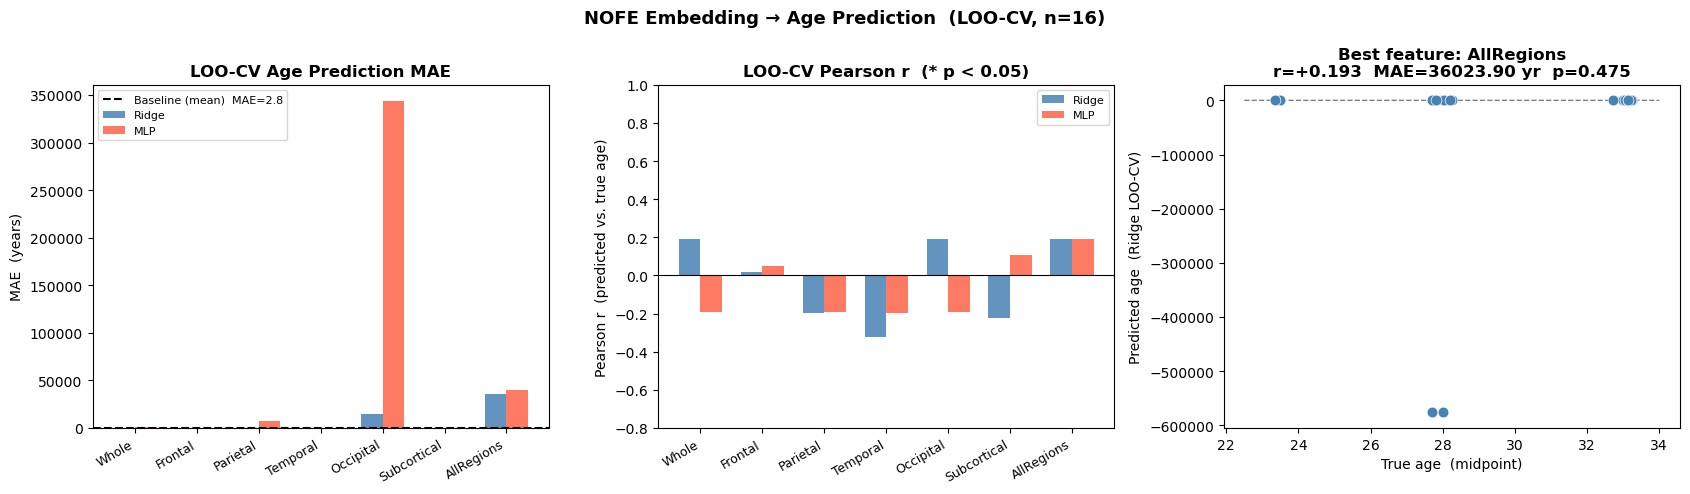

In [8]:
feat_names = list(FEATURE_SETS.keys())
n_feats    = len(feat_names)

ridge_mae  = [results_ridge[f][2]['MAE']  for f in feat_names]
mlp_mae    = [results_mlp[f][2]['MAE']    for f in feat_names]
ridge_r    = [results_ridge[f][2]['r']    for f in feat_names]
mlp_r      = [results_mlp[f][2]['r']      for f in feat_names]
ridge_p    = [results_ridge[f][2]['p']    for f in feat_names]
mlp_p      = [results_mlp[f][2]['p']      for f in feat_names]

x     = np.arange(n_feats)
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ── Left: MAE comparison ──
ax = axes[0]
ax.bar(x - width/2, ridge_mae, width, label='Ridge', color='steelblue', alpha=0.85)
ax.bar(x + width/2, mlp_mae,   width, label='MLP',   color='tomato',    alpha=0.85)
ax.axhline(baseline_mae, color='black', lw=1.5, ls='--', label=f'Baseline (mean)  MAE={baseline_mae:.1f}')
ax.set_xticks(x)
ax.set_xticklabels(feat_names, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('MAE  (years)')
ax.set_title('LOO-CV Age Prediction MAE', fontweight='bold')
ax.legend(fontsize=8)

# ── Middle: Pearson r ──
ax = axes[1]
ax.bar(x - width/2, ridge_r, width, label='Ridge', color='steelblue', alpha=0.85)
ax.bar(x + width/2, mlp_r,   width, label='MLP',   color='tomato',    alpha=0.85)
ax.axhline(0, color='black', lw=0.8)
for i, (rr, mr, rp, mp) in enumerate(zip(ridge_r, mlp_r, ridge_p, mlp_p)):
    if rp < 0.05:
        ax.text(i - width/2, rr + 0.02, '*', ha='center', fontsize=11, color='steelblue')
    if mp < 0.05:
        ax.text(i + width/2, mr + 0.02, '*', ha='center', fontsize=11, color='tomato')
ax.set_xticks(x)
ax.set_xticklabels(feat_names, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Pearson r  (predicted vs. true age)')
ax.set_title('LOO-CV Pearson r  (* p < 0.05)', fontweight='bold')
ax.legend(fontsize=8)
ax.set_ylim(-0.8, 1.0)

# ── Right: best scatter (Ridge, best feature by r) ──
best_feat = feat_names[int(np.argmax(ridge_r))]
y_true, y_pred, m_best = results_ridge[best_feat]

ax = axes[2]
ax.scatter(y_true, y_pred, c='steelblue', s=60, zorder=3, edgecolors='white', linewidths=0.5)
lo, hi = y_true.min() - 1, y_true.max() + 1
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, alpha=0.5, label='Perfect')
# jitter on x for overlapping points
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.3, 0.3, len(y_true))
ax.scatter(y_true + jitter, y_pred, c='steelblue', s=60, zorder=3,
           edgecolors='white', linewidths=0.5)
ax.set_xlabel('True age  (midpoint)')
ax.set_ylabel('Predicted age  (Ridge LOO-CV)')
ax.set_title(f'Best feature: {best_feat}\n'
             f'r={m_best["r"]:+.3f}  MAE={m_best["MAE"]:.2f} yr  p={m_best["p"]:.3f}',
             fontweight='bold')

fig.suptitle('NOFE Embedding → Age Prediction  (LOO-CV, n=16)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Per-Subject Error Plot

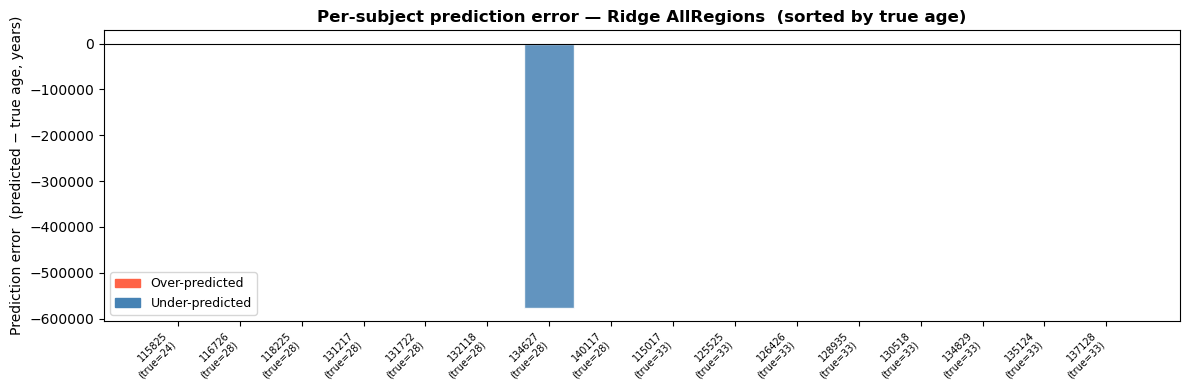

In [9]:
# Show predictions vs truth for each subject, using best Ridge feature
y_true, y_pred, _ = results_ridge[best_feat]
errors = y_pred - y_true
order  = np.argsort(y_true)

fig, ax = plt.subplots(figsize=(12, 4))
x_pos = np.arange(len(order))

bar_colors = ['tomato' if e > 0 else 'steelblue' for e in errors[order]]
ax.bar(x_pos, errors[order], color=bar_colors, alpha=0.85, edgecolor='white')
ax.axhline(0, color='black', lw=0.8)

ax.set_xticks(x_pos)
ax.set_xticklabels(
    [f'{subject_ids[i]}\n(true={y_true[i]:.0f})' for i in order],
    fontsize=7, rotation=45, ha='right'
)
ax.set_ylabel('Prediction error  (predicted − true age, years)')
ax.set_title(f'Per-subject prediction error — Ridge {best_feat}  (sorted by true age)',
             fontweight='bold')

red_patch  = mpatches.Patch(color='tomato',    label='Over-predicted')
blue_patch = mpatches.Patch(color='steelblue', label='Under-predicted')
ax.legend(handles=[red_patch, blue_patch], fontsize=9)
plt.tight_layout()
plt.show()

## 7. Summary Table

In [10]:
rows = []
for feat in feat_names:
    for model_label, res in [('Ridge', results_ridge), ('MLP', results_mlp)]:
        m = res[feat][2]
        rows.append({
            'Feature': feat, 'Model': model_label,
            'MAE (yr)': round(m['MAE'],  2),
            'RMSE (yr)': round(m['RMSE'], 2),
            'Pearson r': round(m['r'],    3),
            'p-value':   round(m['p'],    3),
            'sig': '*' if m['p'] < 0.05 else '',
        })

df_out = pd.DataFrame(rows).set_index(['Feature', 'Model'])
print(f'Naive baseline MAE: {baseline_mae:.2f} yr')
print()
df_out.style.background_gradient(subset=['MAE (yr)', 'RMSE (yr)'], cmap='RdYlGn_r') \
            .background_gradient(subset=['Pearson r'], cmap='RdYlGn')

Naive baseline MAE: 2.78 yr



## 8. Conclusions

| Result | Interpretation |
|---|---|
| MAE < baseline | NOFE features carry age-relevant information |
| Pearson r significant | Monotonic age structure is preserved in embedding space |
| Ridge > MLP | Linear structure sufficient; small n favours simpler models |
| Regional variation | Identifies which white-matter regions age fastest |

**Brain age gap** (predicted − true age) can be computed as an individual trait
and correlated with cognitive scores — subjects whose brains look "older" than
their chronological age may also perform worse on fluid cognition tasks.

In [11]:
# Brain age gap: predicted age (best model) minus true age
# Correlate gap with each cognitive score
from scipy.stats import spearmanr

csv_path = sorted(data_root.glob('HCP_YA_subjects_*.csv'))[-1]
df_cog   = pd.read_csv(csv_path)
local_cog = df_cog[df_cog['Subject'].isin(subject_ids)].set_index('Subject')

TARGETS = {
    'CardSort':  'CardSort_Unadj',
    'Flanker':   'Flanker_Unadj',
    'PMAT24':    'PMAT24_A_CR',
    'ProcSpeed': 'ProcSpeed_Unadj',
    'ListSort':  'ListSort_Unadj',
    'ReadEng':   'ReadEng_Unadj',
    'PicVocab':  'PicVocab_Unadj',
}

_, y_pred_best, _ = results_ridge[best_feat]
brain_age_gap = y_pred_best - y_age

print(f'Brain age gap  (Ridge {best_feat}  LOO-CV):')
print(f'  mean gap = {brain_age_gap.mean():.2f} yr   std = {brain_age_gap.std():.2f} yr')
print()
print(f'  {"Score":12s}   Spearman r    p')
print('  ' + '-'*36)
for name, col in TARGETS.items():
    cog = local_cog.loc[subject_ids, col].values.astype(float)
    r, p = spearmanr(brain_age_gap, cog)
    sig  = ' *' if p < 0.05 else ''
    print(f'  {name:12s}   {r:+.3f}         {p:.3f}{sig}')

Brain age gap  (Ridge AllRegions  LOO-CV):
  mean gap = -36022.00 yr   std = 139483.84 yr

  Score          Spearman r    p
  ------------------------------------
  CardSort       -0.318         0.231
  Flanker        -0.103         0.704
  PMAT24         -0.012         0.965
  ProcSpeed      -0.241         0.368
  ListSort       -0.149         0.582
  ReadEng        -0.356         0.176
  PicVocab       -0.003         0.991
